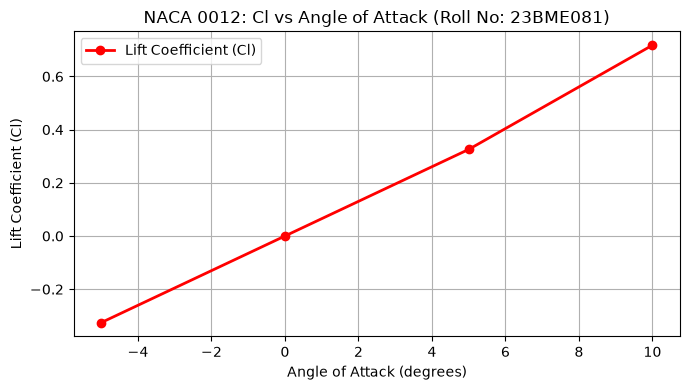

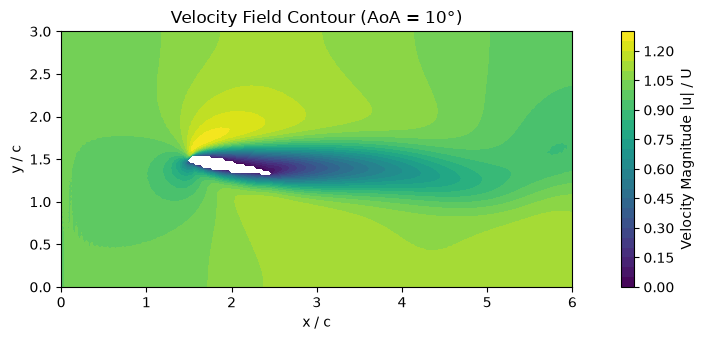

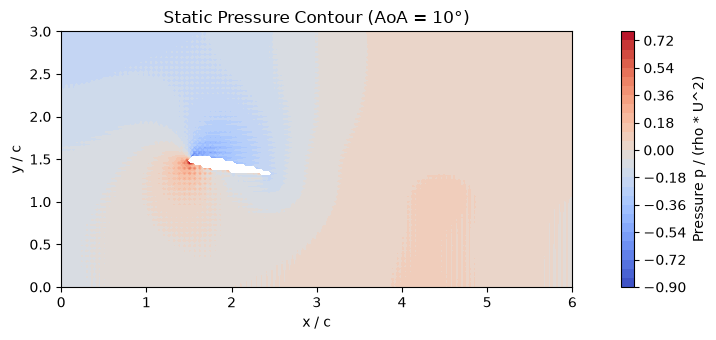

In [4]:
"""
  CFD & HT Lab - Experiment 1
  Topic: Flow over NACA 0012 Airfoil using Immersed Boundary Method
  Student Name : Dev Pateliya
  Roll Number  : 23BME081
  Semester     : 7th Semester (B.Tech Mechanical Engineering)
"""

import numpy as np
import matplotlib.pyplot as plt

c = 1.0
Lx, Ly = 6.0, 3.0
nx, ny = 200, 100
dx = Lx / nx
dy = Ly / ny

xle = Lx / 4.0
Cy = Ly / 2.0
thickness = 0.12

Re = 100.0
u_inlet = 1.0
dt = 0.0015
eta = 0.02 * dt
max_iter = 2500

aoa_list = [-5, 0, 5, 10]

x = np.linspace(0, Lx, nx)
y = np.linspace(0, Ly, ny)
X, Y = np.meshgrid(x, y)


def apply_boundaries(u_field, v_field, p_field):
    u_field[:, 0] = u_inlet
    v_field[:, 0] = 0.0
    p_field[:, 0] = p_field[:, 1]
    
    u_field[:, -1] = u_field[:, -2]
    v_field[:, -1] = v_field[:, -2]
    p_field[:, -1] = 0.0
    
    u_field[0, :] = u_field[1, :]
    v_field[0, :] = 0.0
    p_field[0, :] = p_field[1, :]
    
    u_field[-1, :] = u_field[-2, :]
    v_field[-1, :] = 0.0
    p_field[-1, :] = p_field[-2, :]


def get_rotated_airfoil_mask(aoa_deg):
    rad = np.radians(aoa_deg)
    
    xb = (X - xle) * np.cos(rad) - (Y - Cy) * np.sin(rad)
    yb = (X - xle) * np.sin(rad) + (Y - Cy) * np.cos(rad)
    
    xc = np.clip(xb / c, 0, 1)
    yt = 5.0 * thickness * (
        0.2969 * np.sqrt(xc) - 0.1260 * xc - 
        0.3516 * (xc**2) + 0.2843 * (xc**3) - 0.1036 * (xc**4)
    ) * c
    
    solid_mask = (xb >= 0) & (xb <= c) & (np.abs(yb) < yt)
    return solid_mask.astype(float)


Cl_results = []
Cd_results = []

for aoa in aoa_list:
    u = np.ones((ny, nx)) * u_inlet
    v = np.zeros((ny, nx))
    p = np.zeros((ny, nx))
    
    mask = get_rotated_airfoil_mask(aoa)
    
    for step in range(max_iter):
        apply_boundaries(u, v, p)
        
        u_old = u.copy()
        v_old = v.copy()
        
        u_conv = u_old[1:-1, 1:-1] * (u_old[1:-1, 2:] - u_old[1:-1, :-2]) / (2 * dx) + \
                 v_old[1:-1, 1:-1] * (u_old[2:, 1:-1] - u_old[:-2, 1:-1]) / (2 * dy)
                 
        v_conv = u_old[1:-1, 1:-1] * (v_old[1:-1, 2:] - v_old[1:-1, :-2]) / (2 * dx) + \
                 v_old[1:-1, 1:-1] * (v_old[2:, 1:-1] - v_old[:-2, 1:-1]) / (2 * dy)
                 
        u_diff = (u_old[1:-1, 2:] - 2 * u_old[1:-1, 1:-1] + u_old[1:-1, :-2]) / (dx**2) + \
                 (u_old[2:, 1:-1] - 2 * u_old[1:-1, 1:-1] + u_old[:-2, 1:-1]) / (dy**2)
                 
        v_diff = (v_old[1:-1, 2:] - 2 * v_old[1:-1, 1:-1] + v_old[1:-1, :-2]) / (dx**2) + \
                 (v_old[2:, 1:-1] - 2 * v_old[1:-1, 1:-1] + v_old[:-2, 1:-1]) / (dy**2)
                 
        dp_dx = (p[1:-1, 2:] - p[1:-1, :-2]) / (2 * dx)
        dp_dy = (p[2:, 1:-1] - p[:-2, 1:-1]) / (2 * dy)
        
        penalty = 1.0 + (dt * mask[1:-1, 1:-1] / eta)
        
        u[1:-1, 1:-1] = (u_old[1:-1, 1:-1] + dt * (-u_conv + (1.0 / Re) * u_diff - dp_dx)) / penalty
        v[1:-1, 1:-1] = (v_old[1:-1, 1:-1] + dt * (-v_conv + (1.0 / Re) * v_diff - dp_dy)) / penalty
        
        div = (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx) + (v[2:, 1:-1] - v[:-2, 1:-1]) / (2 * dy)
        p_corr = np.zeros((ny, nx))
        
        for _ in range(10):
            p_corr[1:-1, 1:-1] = 0.25 * (
                p_corr[1:-1, 2:] + p_corr[1:-1, :-2] +
                p_corr[2:, 1:-1] + p_corr[:-2, 1:-1] - (dx**2) * div / dt
            )
            
        u[1:-1, 1:-1] -= dt * (p_corr[1:-1, 2:] - p_corr[1:-1, :-2]) / (2 * dx)
        v[1:-1, 1:-1] -= dt * (p_corr[2:, 1:-1] - p_corr[:-2, 1:-1]) / (2 * dy)
        p += p_corr
        
        Fx = np.sum(mask * u) / eta * dx * dy
        Fy = np.sum(mask * v) / eta * dx * dy
        
        Cd = 2.0 * Fx / (u_inlet**2 * c)
        Cl = 2.0 * Fy / (u_inlet**2 * c)
        
    Cl_results.append(Cl)
    Cd_results.append(Cd)

plt.figure(figsize=(7, 4))
plt.plot(aoa_list, Cl_results, 'ro-', linewidth=2, label='Lift Coefficient (Cl)')
plt.xlabel('Angle of Attack (degrees)')
plt.ylabel('Lift Coefficient (Cl)')
plt.title('NACA 0012: Cl vs Angle of Attack (Roll No: 23BME081)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

speed = np.sqrt(u**2 + v**2)
speed[mask == 1] = np.nan

p_display = p.copy()
p_display[mask == 1] = np.nan

plt.figure(figsize=(10, 3.5))
plt.contourf(X, Y, speed, levels=30, cmap='viridis')
plt.colorbar(label='Velocity Magnitude |u| / U')
plt.title(f'Velocity Field Contour (AoA = {aoa_list[-1]}°)')
plt.xlabel('x / c')
plt.ylabel('y / c')
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3.5))
plt.contourf(X, Y, p_display, levels=30, cmap='coolwarm')
plt.colorbar(label='Pressure p / (rho * U^2)')
plt.title(f'Static Pressure Contour (AoA = {aoa_list[-1]}°)')
plt.xlabel('x / c')
plt.ylabel('y / c')
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.show()